# Pneumonia Detection using Convolutional Neural Network (CNN)

**Purpose:** Train a binary image-classification model using chest X-ray images and evaluate it with accuracy, precision, recall, F1-score, loss, and a confusion matrix.

**Classes:** `NORMAL` and `PNEUMONIA`

## Before running
1. Extract your dataset so that its folders look like this:

   ```text
   dtataset/
       chest_xray/
           train/
               NORMAL/
               PNEUMONIA/
           test/
               NORMAL/
               PNEUMONIA/
   ```

2. If your folder is named `dataset` rather than `dtataset`, change `DATASET_DIR` in the configuration cell below.
3. Run the notebook from top to bottom.
4. Training can take time. A GPU is helpful but not required.

> **Important:** All reported scores and graphs are generated by running this notebook on your dataset. Do not use example or assumed performance values. This is an educational screening-support project, not a clinical diagnostic system.


## 1. Install and import dependencies

TensorFlow must be installed in the Python environment used by this notebook. The next cell installs the additional evaluation and plotting packages.

In [1]:
%pip install -q scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


## 2. Configuration

Check `DATASET_DIR` carefully. The path below follows the directory used in the original notebook.

In [3]:
# Dataset location (change this if your folder has a different name)

TRAIN_DIR = os.path.join("dataset/chest_xray/train")
TEST_DIR = os.path.join("dataset/chest_xray/test")

IMG_SIZE = 150
BATCH_SIZE = 32
EPOCHS = 15
SEED = 123

# Reproducibility
tf.keras.utils.set_random_seed(SEED)

# Check that the required folders exist
for folder in [TRAIN_DIR, TEST_DIR]:
    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f"Folder not found: {folder}\n"
            "Check DATASET_DIR and make sure the dataset is extracted correctly."
        )

print("Training folder:", TRAIN_DIR)
print("Test folder:", TEST_DIR)

Training folder: dataset/chest_xray/train
Test folder: dataset/chest_xray/test


## 3. Load and preprocess the images

Images are resized to **150 × 150**, converted to **grayscale**, and loaded in batches of **32**. Twenty percent of the training directory is reserved for validation. The test directory remains separate.

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Capture class names before applying prefetch.
class_names = train_ds.class_names
print("Class names:", class_names)

if len(class_names) != 2:
    raise ValueError(f"Expected exactly 2 classes, but found: {class_names}")

# The sigmoid output is interpreted as class index 1.
print("Label mapping: 0 =", class_names[0], "| 1 =", class_names[1])

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Class names: ['NORMAL', 'PNEUMONIA']
Label mapping: 0 = NORMAL | 1 = PNEUMONIA


## 4. Inspect sample images

This optional visualization checks that the images and labels have loaded correctly.

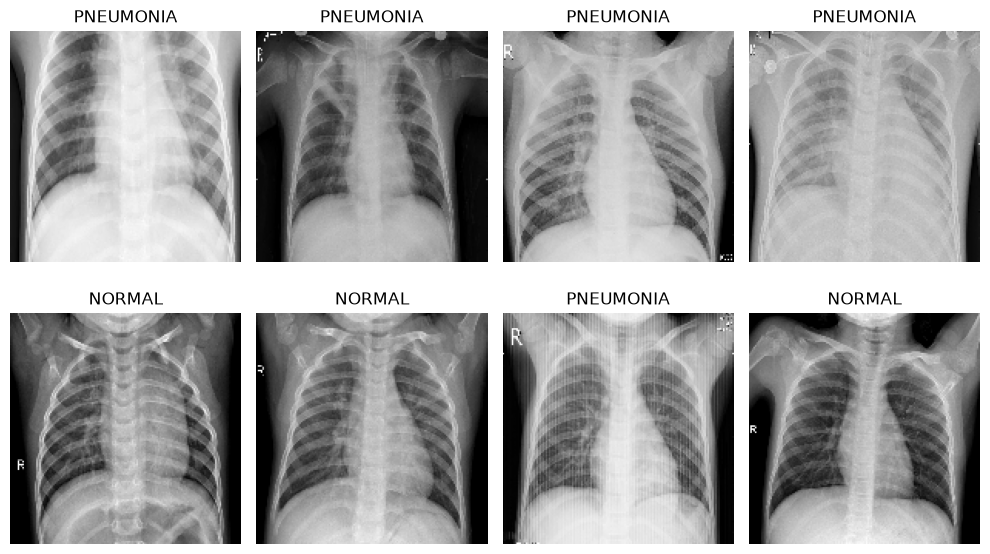

In [5]:
plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    number_to_show = min(8, images.shape[0])
    for i in range(number_to_show):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(tf.squeeze(images[i]), cmap="gray")
        label_index = int(labels[i].numpy()[0])
        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Build the CNN model

The model uses three convolution and max-pooling blocks to learn image features, followed by dense layers for binary classification. A sigmoid output produces a probability for class index 1.

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),

    # Normalize pixel values from [0, 255] to [0, 1]
    tf.keras.layers.Rescaling(1.0 / 255),

    # Convolution block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification head
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,827,905 (18.42 MB)

 Trainable params: 4,827,905 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the model

Binary cross-entropy is used because the task has two classes. Precision and recall are also tracked during training.

In [7]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

## 7. Train the model

Early stopping monitors validation loss and restores the best weights if validation loss stops improving.

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/15


c:\Users\lenov\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 265ms/step - accuracy: 0.8962 - loss: 0.2620 - precision: 0.9002 - recall: 0.9657 - val_accuracy: 0.9540 - val_loss: 0.1143 - val_precision: 0.9885 - val_recall: 0.9519
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 31s 235ms/step - accuracy: 0.9528 - loss: 0.1359 - precision: 0.9656 - recall: 0.9703 - val_accuracy: 0.9703 - val_loss: 0.0685 - val_precision: 0.9827 - val_recall: 0.9790
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 31s 233ms/step - accuracy: 0.9595 - loss: 0.1149 - precision: 0.9707 - recall: 0.9742 - val_accuracy: 0.9664 - val_loss: 0.0854 - val_precision: 0.9924 - val_recall: 0.9642
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 29s 224ms/step - accuracy: 0.9688 - loss: 0.0909 - precision: 0.9785 - recall: 0.9791 - val_accuracy: 0.9703 - val_loss: 0.0740 - val_precision: 0.9937 - val_recall: 0.9679
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 30s 225ms/step - accuracy: 0.9720 - loss: 0.0773 - precision: 0.9798 - recall: 0.9821 - val_accuracy: 0.9760 - val_loss

## 8. Plot training and validation accuracy

**Suggested paper caption:** *Fig. 7. Training and validation accuracy of the CNN model over successive epochs.*

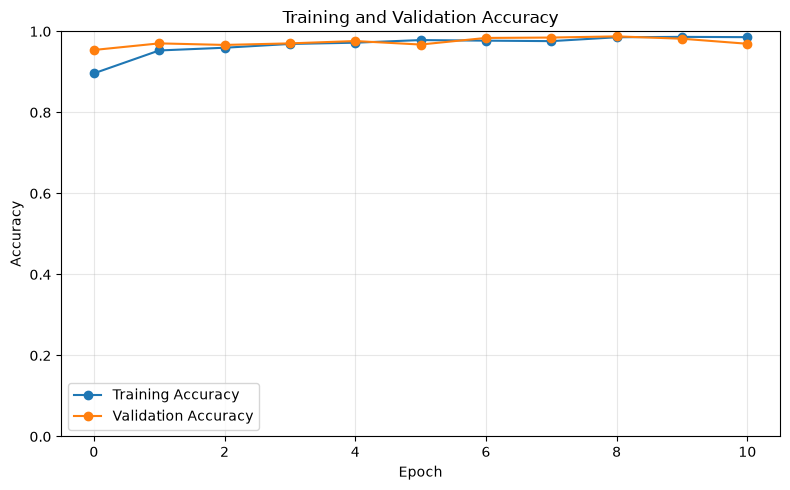

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("accuracy_graph.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Plot training and validation loss

**Suggested paper caption:** *Fig. 8. Training and validation loss of the CNN model over successive epochs.*

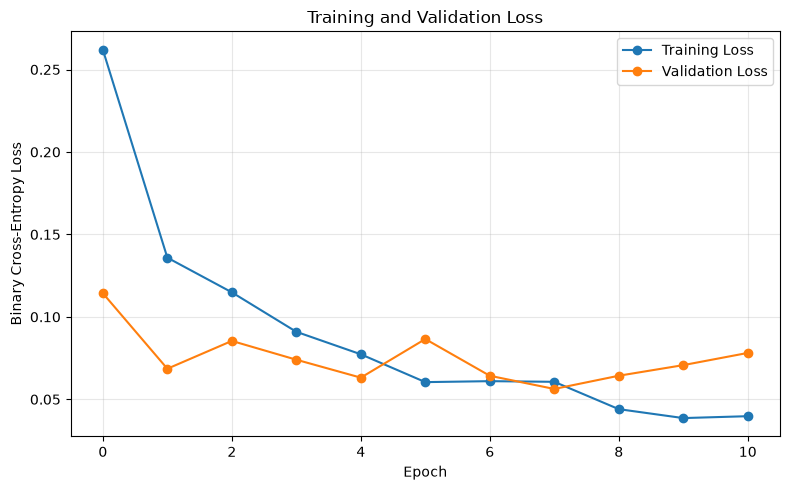

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("loss_graph.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Evaluate on the separate test dataset

This reports the test loss, accuracy, precision, and recall calculated by Keras.

In [11]:
test_results = model.evaluate(test_ds, return_dict=True, verbose=1)

print("\nTEST DATASET RESULTS")
print("-" * 30)
for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.7420 - loss: 1.4539 - precision: 0.7093 - recall: 0.9949

TEST DATASET RESULTS
------------------------------
accuracy: 0.7420
loss: 1.4539
precision: 0.7093
recall: 0.9949


## 11. Calculate precision, recall, F1-score, and confusion matrix

The model's sigmoid output is converted to a class prediction using a threshold of 0.5. The class order is the alphabetical folder order printed in Section 3.

In [12]:
# Collect true labels in the same order as the unshuffled test dataset
y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

# Predict probabilities and convert them to class indices
y_prob = model.predict(test_ds, verbose=1).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

# Calculate metrics
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(y_true, y_pred, zero_division=0)
test_recall = recall_score(y_true, y_pred, zero_division=0)
test_f1 = f1_score(y_true, y_pred, zero_division=0)

print("TEST PERFORMANCE")
print("-" * 30)
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}  (positive class: {class_names[1]})")
print(f"Recall   : {test_recall:.4f}  (positive class: {class_names[1]})")
print(f"F1-score : {test_f1:.4f}  (positive class: {class_names[1]})")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step
TEST PERFORMANCE
------------------------------
Accuracy : 0.7420
Precision: 0.7093  (positive class: PNEUMONIA)
Recall   : 0.9949  (positive class: PNEUMONIA)
F1-score : 0.8282  (positive class: PNEUMONIA)

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.97      0.32      0.48       234
   PNEUMONIA       0.71      0.99      0.83       390

    accuracy                           0.74       624
   macro avg       0.84      0.66      0.66       624
weighted avg       0.81      0.74      0.70       624

Confusion matrix (rows = actual, columns = predicted):
[[ 75 159]
 [  2 388]]


## 12. Plot the confusion matrix

**Suggested paper caption:** *Fig. 9. Confusion matrix for binary pneumonia classification.*

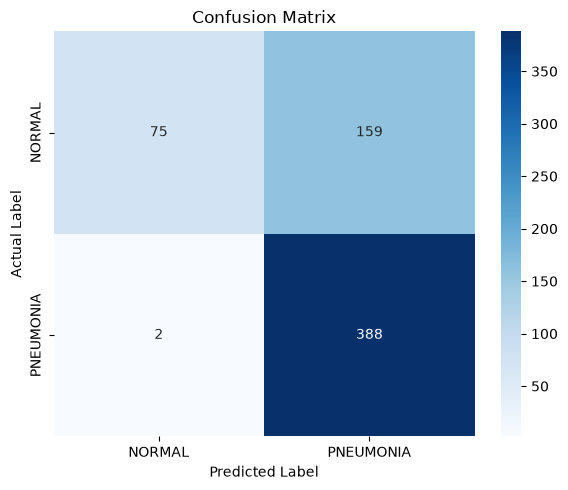

In [13]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Plot the test performance metrics

Precision, recall, and F1-score below refer to the positive class (`class_names[1]`).

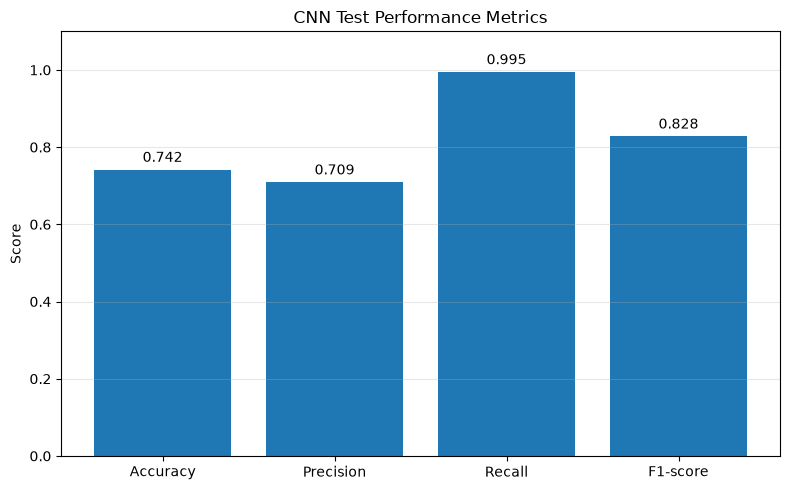

In [14]:
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
metric_values = [test_accuracy, test_precision, test_recall, test_f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metric_names, metric_values)
plt.title("CNN Test Performance Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.1)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("performance_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

## 14. View example predictions

This displays a few test images with their actual and predicted labels.

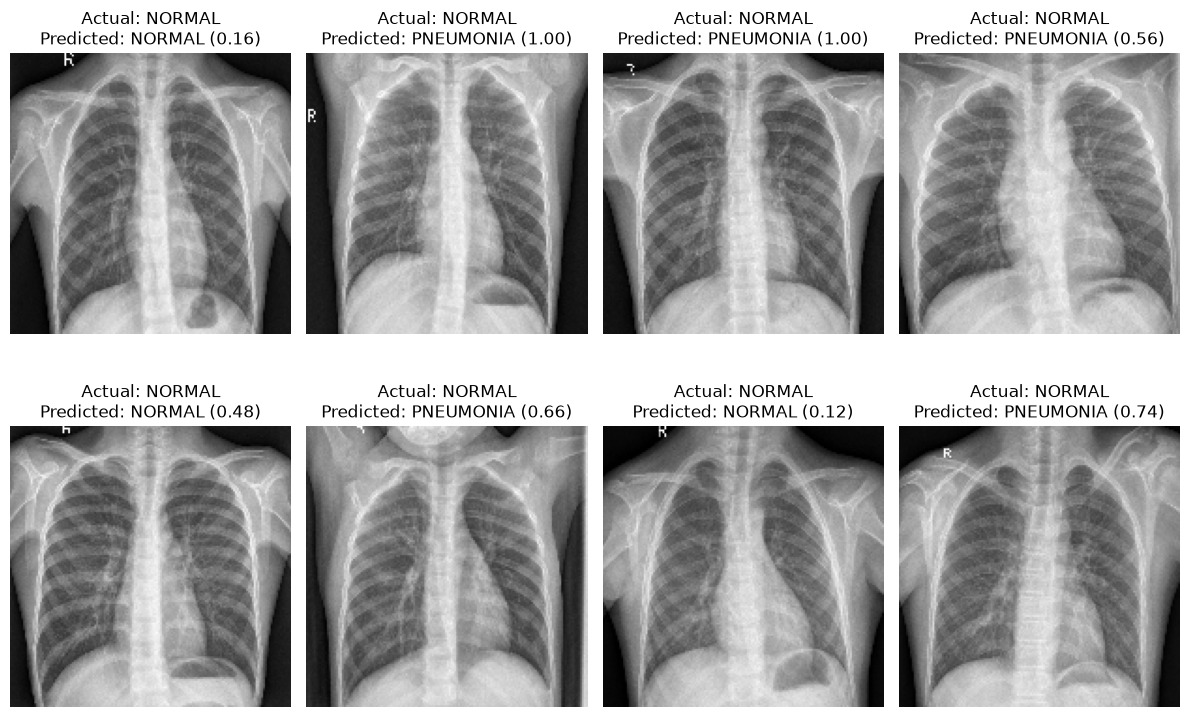

In [15]:
plt.figure(figsize=(12, 8))

shown = 0
for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0).reshape(-1)
    predictions = (probabilities >= 0.5).astype(int)

    for i in range(images.shape[0]):
        if shown >= 8:
            break

        ax = plt.subplot(2, 4, shown + 1)
        plt.imshow(tf.squeeze(images[i]), cmap="gray")

        actual_index = int(labels[i].numpy()[0])
        predicted_index = int(predictions[i])

        plt.title(
            f"Actual: {class_names[actual_index]}\n"
            f"Predicted: {class_names[predicted_index]} ({probabilities[i]:.2f})"
        )
        plt.axis("off")
        shown += 1

    if shown >= 8:
        break

plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

## 15. Save the trained model and results

The model, metric summary, and graphs are saved in the notebook's current working directory.

In [16]:
# Save trained model
model.save("pneumonia_detection_cnn.keras")

# Save metrics to CSV
metrics_df = pd.DataFrame({
    "Metric": ["Test Loss", "Test Accuracy", "Test Precision", "Test Recall", "Test F1-score"],
    "Value": [
        test_results["loss"],
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})
metrics_df.to_csv("pneumonia_test_metrics.csv", index=False)

# Save confusion matrix as CSV
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{name}" for name in class_names],
    columns=[f"Predicted_{name}" for name in class_names]
)
cm_df.to_csv("pneumonia_confusion_matrix.csv")

print("Saved:")
print("- pneumonia_detection_cnn.keras")
print("- pneumonia_test_metrics.csv")
print("- pneumonia_confusion_matrix.csv")
print("- accuracy_graph.png")
print("- loss_graph.png")
print("- confusion_matrix.png")
print("- performance_metrics.png")
print("- sample_predictions.png")

Saved:
- pneumonia_detection_cnn.keras
- pneumonia_test_metrics.csv
- pneumonia_confusion_matrix.csv
- accuracy_graph.png
- loss_graph.png
- confusion_matrix.png
- performance_metrics.png
- sample_predictions.png


## 16. Results to report in the IEEE paper

Use the actual values printed in Sections 10 and 11. Do not fill this table with guessed values.

| Metric | Value from this run |
|---|---|
| Training accuracy | Read final/best value from `history.history["accuracy"]` |
| Validation accuracy | Read final/best value from `history.history["val_accuracy"]` |
| Test accuracy | `test_accuracy` |
| Test loss | `test_results["loss"]` |
| Test precision | `test_precision` |
| Test recall | `test_recall` |
| Test F1-score | `test_f1` |

**Suggested Results and Discussion text (complete it after running):**

"The CNN model was evaluated on a separate test dataset using accuracy, precision, recall, and F1-score. Training and validation accuracy and loss curves were examined to understand the model's learning behaviour. The confusion matrix was used to inspect correct classifications and misclassifications for the NORMAL and PNEUMONIA classes. The measured values from the experiment are reported in the accompanying table."

### Important interpretation note
- In this notebook, class index `1` is the second class in `class_names` (normally `PNEUMONIA`).
- The printed precision, recall, and F1-score are for that positive class. The classification report also gives per-class and macro/weighted averages.
- A high validation or test score alone does not establish clinical reliability. Dataset leakage, class imbalance, and performance on external hospitals must be considered.
- The architecture and results in your paper must match the code and actual run. Do not describe unimplemented layers or report results that were not produced by this notebook.
